# Market Basket Analysis with Python- Amazon

In [111]:
# Importing the prerequisites
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [112]:
from mlxtend.frequent_patterns import apriori, association_rules
import sys
print(sys.version)

3.12.4 | packaged by Anaconda, Inc. | (main, Jun 18 2024, 15:03:56) [MSC v.1929 64 bit (AMD64)]


In [113]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

In [114]:
# To load the data in Python
df = pd.read_csv('amazon.csv')

In [115]:
# To check how the data looks
df.head(2)

,Timestamp,age,Gender,Purchase_Frequency,Purchase_Categories,Personalized_Recommendation_Frequency,Browsing_Frequency,Product_Search_Method,Search_Result_Exploration,Customer_Reviews_Importance,...,Review_Left,Review_Reliability,Review_Helpfulness,Personalized_Recommendation_Frequency,Recommendation_Helpfulness,Rating_Accuracy,Shopping_Satisfaction,Service_Appreciation,Improvement_Areas,transaction
0,2023/06/08 7:50:55 PM GMT+5:30,65,Prefer not to say,Less than once a month,Clothing and Fashion,Yes,Multiple times a day,Keyword,Multiple pages,2,...,Yes,Moderately,No,2,Sometimes,4,4,Competitive prices,better app interface and lower shipping charges,778242
1,2023/06/09 9:37:44 AM GMT+5:30,20,Male,Once a week,Groceries and Gourmet Food;Beauty and Personal...,No,Rarely,Filter,First page,3,...,Yes,Heavily,Yes,1,Sometimes,4,5,Quick delivery,Scrolling option would be much better than goi...,193482


In [116]:
# Check shape and column names
print(df.shape)
print(df.columns)

(800, 24)
Index(['Timestamp', 'age', 'Gender', 'Purchase_Frequency',
       'Purchase_Categories', 'Personalized_Recommendation_Frequency',
       'Browsing_Frequency', 'Product_Search_Method',
       'Search_Result_Exploration', 'Customer_Reviews_Importance',
       'Add_to_Cart_Browsing', 'Cart_Completion_Frequency',
       'Cart_Abandonment_Factors', 'Saveforlater_Frequency', 'Review_Left',
       'Review_Reliability', 'Review_Helpfulness',
       'Personalized_Recommendation_Frequency ', 'Recommendation_Helpfulness',
       'Rating_Accuracy ', 'Shopping_Satisfaction', 'Service_Appreciation',
       'Improvement_Areas', 'transaction'],
      dtype='object')


# Task 1: Data Cleaning and Preparation

In [136]:
# Check and remove duplicates
print(df.duplicated().sum())

0


No duplicatea are found

In [139]:
# Standardizing the categorical entries
categorical_cols = ['Gender', 'Purchase_Frequency', 'Browsing_Frequency', 'Recommendation_Helpfulness', 'Review_Helpfulness']

for col in categorical_cols:
    df[col] = df[col].str.lower().str.strip() # .str.lower() converts the values to lower case then .str.strip() removes the trailing spaces from values

In [141]:
df.head(2)

,Timestamp,age,Gender,Purchase_Frequency,Purchase_Categories,Personalized_Recommendation_Frequency,Browsing_Frequency,Product_Search_Method,Search_Result_Exploration,Customer_Reviews_Importance,...,Review_Left,Review_Reliability,Review_Helpfulness,Personalized_Recommendation_Frequency,Recommendation_Helpfulness,Rating_Accuracy,Shopping_Satisfaction,Service_Appreciation,Improvement_Areas,transaction
0,2023/06/08 7:50:55 PM GMT+5:30,65,prefer not to say,less than once a month,Clothing and Fashion,Yes,multiple times a day,Keyword,Multiple pages,2,...,Yes,Moderately,no,2,sometimes,4,4,Competitive prices,better app interface and lower shipping charges,778242
1,2023/06/09 9:37:44 AM GMT+5:30,20,male,once a week,Groceries and Gourmet Food;Beauty and Personal...,No,rarely,Filter,First page,3,...,Yes,Heavily,yes,1,sometimes,4,5,Quick delivery,Scrolling option would be much better than goi...,193482


In [143]:
# Handling the missing values
df.isna().sum()

Timestamp                                   0
age                                         0
Gender                                      0
Purchase_Frequency                          0
Purchase_Categories                         0
Personalized_Recommendation_Frequency       0
Browsing_Frequency                          0
Product_Search_Method                     157
Search_Result_Exploration                   0
Customer_Reviews_Importance                 0
Add_to_Cart_Browsing                        0
Cart_Completion_Frequency                   0
Cart_Abandonment_Factors                    0
Saveforlater_Frequency                      0
Review_Left                                 0
Review_Reliability                          0
Review_Helpfulness                          0
Personalized_Recommendation_Frequency       0
Recommendation_Helpfulness                  0
Rating_Accuracy                             0
Shopping_Satisfaction                       0
Service_Appreciation              

Only the Product_Search_Method has missing values so we will replace it with the mode value.

In [146]:
df['Product_Search_Method'] = df['Product_Search_Method'].fillna(df['Product_Search_Method'].mode()[0]) 
# fillna replaces the missing values with the mode values of that column

In [148]:
# Standardize Product_Search_Method formatting
df['Product_Search_Method'] = (df['Product_Search_Method'].str.lower().str.replace('&',',', regex = False).str.strip())
df.head(2)

,Timestamp,age,Gender,Purchase_Frequency,Purchase_Categories,Personalized_Recommendation_Frequency,Browsing_Frequency,Product_Search_Method,Search_Result_Exploration,Customer_Reviews_Importance,...,Review_Left,Review_Reliability,Review_Helpfulness,Personalized_Recommendation_Frequency,Recommendation_Helpfulness,Rating_Accuracy,Shopping_Satisfaction,Service_Appreciation,Improvement_Areas,transaction
0,2023/06/08 7:50:55 PM GMT+5:30,65,prefer not to say,less than once a month,Clothing and Fashion,Yes,multiple times a day,keyword,Multiple pages,2,...,Yes,Moderately,no,2,sometimes,4,4,Competitive prices,better app interface and lower shipping charges,778242
1,2023/06/09 9:37:44 AM GMT+5:30,20,male,once a week,Groceries and Gourmet Food;Beauty and Personal...,No,rarely,filter,First page,3,...,Yes,Heavily,yes,1,sometimes,4,5,Quick delivery,Scrolling option would be much better than goi...,193482


In [150]:
# Rename duplicate or misformatted columns
df = df.rename(columns = {
    'Personalized_Recommendation_Frequency':'Recommendation_Received',
    'Personalized_Recommendation_Frequency ':'Recommendation_Frequency_Score'
})

#Removing the trailing spaces from all columns
df.columns = df.columns.str.strip()

df.head(2)

,Timestamp,age,Gender,Purchase_Frequency,Purchase_Categories,Recommendation_Received,Browsing_Frequency,Product_Search_Method,Search_Result_Exploration,Customer_Reviews_Importance,...,Review_Left,Review_Reliability,Review_Helpfulness,Recommendation_Frequency_Score,Recommendation_Helpfulness,Rating_Accuracy,Shopping_Satisfaction,Service_Appreciation,Improvement_Areas,transaction
0,2023/06/08 7:50:55 PM GMT+5:30,65,prefer not to say,less than once a month,Clothing and Fashion,Yes,multiple times a day,keyword,Multiple pages,2,...,Yes,Moderately,no,2,sometimes,4,4,Competitive prices,better app interface and lower shipping charges,778242
1,2023/06/09 9:37:44 AM GMT+5:30,20,male,once a week,Groceries and Gourmet Food;Beauty and Personal...,No,rarely,filter,First page,3,...,Yes,Heavily,yes,1,sometimes,4,5,Quick delivery,Scrolling option would be much better than goi...,193482


In [152]:
# Converting numerical rating columns to appropriate numeric types
numeric_cols  = [
    'Customer_Reviews_Importance',
    'Shopping_Satisfaction',
    'Rating_Accuracy',
    'Recommendation_Frequency_Score'
]
df[numeric_cols] = df[numeric_cols].apply(pd.to_numeric, errors = 'coerce') #changes the above 4 columns to numeric type

In [154]:
# Give the info about the data type
df.dtypes

Timestamp                         object
age                                int64
Gender                            object
Purchase_Frequency                object
Purchase_Categories               object
Recommendation_Received           object
Browsing_Frequency                object
Product_Search_Method             object
Search_Result_Exploration         object
Customer_Reviews_Importance        int64
Add_to_Cart_Browsing              object
Cart_Completion_Frequency         object
Cart_Abandonment_Factors          object
Saveforlater_Frequency            object
Review_Left                       object
Review_Reliability                object
Review_Helpfulness                object
Recommendation_Frequency_Score     int64
Recommendation_Helpfulness        object
Rating_Accuracy                    int64
Shopping_Satisfaction              int64
Service_Appreciation              object
Improvement_Areas                 object
transaction                        int64
dtype: object

Task 1 mainly focused on cleaning the survey data by removing the duplicate responses, standardizing the categorical variables, handling the missing and inconsistent values, correcting the column name issues like duplicate column names and removing trailing spaces and converting the rating columns into numeric format for analysis.

# Task 2: Descriptive Behavior Analysis

In [158]:
# Age Summary
print(df['age'].describe())

print('-----------------------')

# Gender Distribution
print(df['Gender'].value_counts())

count    800.000000
mean      35.170000
std       18.916485
min        3.000000
25%       19.000000
50%       35.500000
75%       51.000000
max       67.000000
Name: age, dtype: float64
-----------------------
Gender
male                 209
others               202
female               197
prefer not to say    192
Name: count, dtype: int64


Amazon's customer base spans a wide age range, with strong concentration across mid-30s. This suggests the platform appeals to both young adults and mature users, requiring diversified product offerings and marketing strategies.

The gender distribution of respondents is fairly balanced, with male, female, and other categories having similar representation. A significant proportion of users selected “Others” or “Prefer not to say,” indicating inclusivity and privacy awareness among Amazon customers.

In [161]:
df[df['age'] <= 10].head(3) # To filter out data of age below 10

,Timestamp,age,Gender,Purchase_Frequency,Purchase_Categories,Recommendation_Received,Browsing_Frequency,Product_Search_Method,Search_Result_Exploration,Customer_Reviews_Importance,...,Review_Left,Review_Reliability,Review_Helpfulness,Recommendation_Frequency_Score,Recommendation_Helpfulness,Rating_Accuracy,Shopping_Satisfaction,Service_Appreciation,Improvement_Areas,transaction
21,2023/06/07 5:58:12 PM GMT+5:30,8,others,once a month,Clothing and Fashion;others,Sometimes,few times a month,categories,First page,1,...,No,Occasionally,sometimes,1,no,1,3,User-friendly website/app interface,Reducing packaging waste,123738
27,2023/06/05 9:56:02 PM GMT+5:30,9,others,once a week,Groceries and Gourmet Food;Beauty and Personal...,Yes,rarely,keyword,Multiple pages,3,...,Yes,Never,sometimes,3,yes,3,4,.,No problems with Amazon,705210
30,2023/06/05 9:56:58 AM GMT+5:30,5,male,once a month,Clothing and Fashion;Home and Kitchen;others,Sometimes,few times a week,keyword,Multiple pages,3,...,Yes,Rarely,no,4,yes,1,1,All the above,Scrolling option would be much better than goi...,956949


A few extreme age values were observed and treated as survey anomalies.

In [164]:
# Purchase Frequency Analysis
df['Purchase_Frequency'].value_counts()

Purchase_Frequency
once a month              168
multiple times a week     159
once a week               159
few times a month         158
less than once a month    156
Name: count, dtype: int64

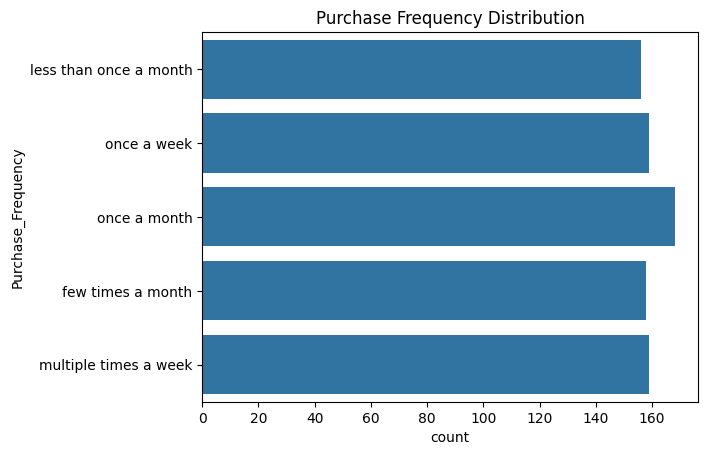

In [166]:
sns.countplot(y = 'Purchase_Frequency', data = df)
plt.title('Purchase Frequency Distribution')
plt.show()

Purchase frequency is evenly distributed across categories, indicating diverse shopping behaviors among Amazon customers. A small portion of users shop weekly or multiple times a week, reflecting strong engagement, while infrequent shoppers present opportunities for targeted retention strategies.

In [168]:
# Popular Product Categories
df['Purchase_Categories'].value_counts().head() # Will show only 5 Purchase categories type

Purchase_Categories
Clothing and Fashion;others                             39
others                                                  38
Beauty and Personal Care;Clothing and Fashion;others    38
Clothing and Fashion;Home and Kitchen;others            36
Groceries and Gourmet Food;Clothing and Fashion         34
Name: count, dtype: int64

The purchase category analysis shows that customers frequently buy products across multiple categories rather than a single category. Clothing and Fashion emerges as a dominant category, often appearing in combination with groceries, beauty, and home-related products. This multi-category purchasing behavior highlights strong cross-selling opportunities and justifies the use of Market Basket Analysis in later stages

In [170]:
# Product Search Methods
df['Product_Search_Method'].value_counts()

Product_Search_Method
keyword       327
categories    163
filter        161
others        149
Name: count, dtype: int64

Customers use a mix of product search methods, with keyword search being slightly more prevalent, followed closely by category browsing and filter-based search. This indicates that both intent-driven and exploratory shopping behaviors are common, emphasizing the need for an optimized and consistent discovery experience across all search methods.

In [175]:
# Cart Abandoment Factors
df['Cart_Abandonment_Factors'].value_counts()

Cart_Abandonment_Factors
High shipping costs                           224
Found a better price elsewhere                206
Changed my mind or no longer need the item    194
others                                        176
Name: count, dtype: int64

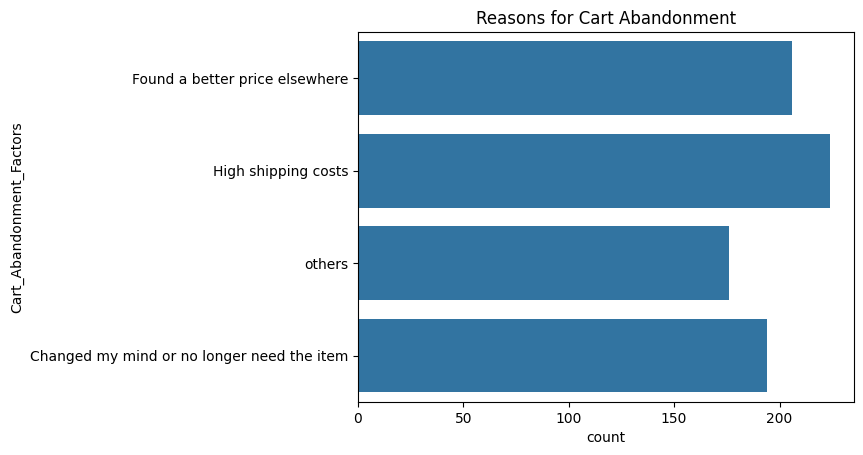

In [176]:
sns.countplot(y='Cart_Abandonment_Factors', data=df)
plt.title('Reasons for Cart Abandonment')
plt.show()

The primary reasons for cart abandonment are high shipping costs and better prices available elsewhere, highlighting strong price sensitivity among customers. Behavioral indecision also plays a significant role, suggesting opportunities to improve product information, pricing transparency, and checkout incentives.

In [180]:
# Satisfaction and Ratings
rating_cols = [
    'Shopping_Satisfaction',
    'Customer_Reviews_Importance',
    'Rating_Accuracy',
    'Recommendation_Frequency_Score'
]

df[rating_cols].agg(['mean', 'median']) # To find the mean and median of rating columns

,Shopping_Satisfaction,Customer_Reviews_Importance,Rating_Accuracy,Recommendation_Frequency_Score
mean,3.0125,3.05875,2.96875,2.9525
median,3.0000,3.00000,3.00000,3.0000


The Mean and Median values for all the numeric columns are centered around 3, indicating a moderate overall customer satisfaction. Reviews are perceived as slightly more influential than personalized recommendations, while rating accuracy shows room for improvement, highlighting potential opportunities to enhance trust and personalization mechanisms.

In [183]:
# To get the summary statistics of the dataset
df.describe()

,age,Customer_Reviews_Importance,Recommendation_Frequency_Score,Rating_Accuracy,Shopping_Satisfaction,transaction
count,800.000000,800.000000,800.000000,800.000000,800.00000,800.000000
mean,35.170000,3.058750,2.952500,2.968750,3.01250,556906.991250
std,18.916485,1.408111,1.420481,1.403651,1.40706,261823.943299
min,3.000000,1.000000,1.000000,1.000000,1.00000,101391.000000
25%,19.000000,2.000000,2.000000,2.000000,2.00000,332074.750000
50%,35.500000,3.000000,3.000000,3.000000,3.00000,563278.500000
75%,51.000000,4.000000,4.000000,4.000000,4.00000,780725.250000
max,67.000000,5.000000,5.000000,5.000000,5.00000,999892.000000


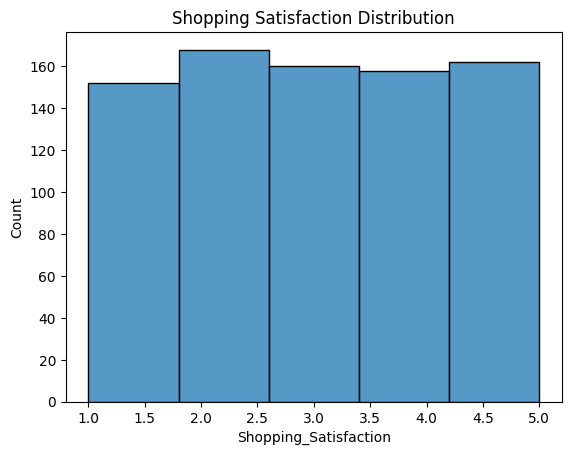

In [185]:
sns.histplot(df['Shopping_Satisfaction'], bins=5)
plt.title('Shopping Satisfaction Distribution')
plt.show()

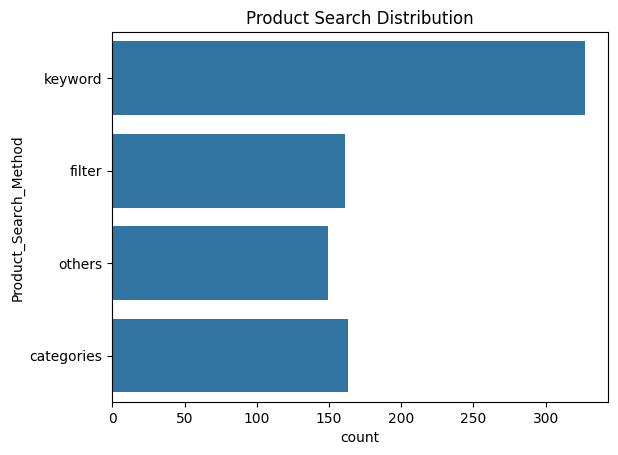

In [186]:
sns.countplot(df['Product_Search_Method'])
plt.title('Product Search Distribution')
plt.show()

Task 2 focused on understanding customer demographics, purchasing behavior, browsing preferences, satisfaction levels, and key behavioral trends through descriptive statistics and visual analysis.

# Task 3: Customer Segmentation and Profiling

In [190]:
# Satisfaction Level
def satisfaction_level(score):
    if score >= 4:
        return 'High'
    elif score == 3:
        return 'Medium'
    else:
        return 'Low'

df['Satisfaction_Level'] = df['Shopping_Satisfaction'].apply(satisfaction_level) 
# Above defined function is applied here using apply() method.

In [192]:
# Purchase Level
def purchase_level(freq):
    freq = freq.lower()
    if freq in ['multiple times a week', 'once a week']:
        return 'High'
    elif freq == 'few times a month':
        return 'Medium'
    else:
        'Low'

df['Purchase_Frequency_Level'] = df['Purchase_Frequency'].apply(purchase_level)

#### Customer Profiles

In [196]:
def customer_segment(row):
    if row['Purchase_Frequency_Level'] == 'High' and row['Satisfaction_Level'] == 'High':
        return 'Frequent Buyers'
    elif row['Purchase_Frequency_Level'] == 'Medium' and row['Satisfaction_Level'] in ['Medium', 'High']:
        return 'Occational Shoppers'
    elif row['Satisfaction_Level'] == 'Low':
        return 'At-Risk Customers'
    else:
        return 'Others'

df['Customer_Segment'] = df.apply(customer_segment, axis = 1) 
# Above defined function is applied here using apply() method on rows of the dataset.

In [198]:
df['Customer_Segment'].value_counts()

Customer_Segment
At-Risk Customers      320
Others                 263
Frequent Buyers        135
Occational Shoppers     82
Name: count, dtype: int64

Customers can be broadly classified into frequent buyers, occasional shoppers, and at-risk customers based on their purchasing behavior and satisfaction levels. Frequent buyers represent loyal and high-value users, while at-risk customers exhibit lower satisfaction and may require targeted retention strategies.

In [201]:
# Analyze demographic or behavioral differences across segments
df.groupby('Customer_Segment')[[
    'Shopping_Satisfaction',
    'Recommendation_Frequency_Score'
]].mean().round(2)

,Shopping_Satisfaction,Recommendation_Frequency_Score
Customer_Segment,,
At-Risk Customers,1.52,2.92
Frequent Buyers,4.51,3.05
Occational Shoppers,3.88,3.11
Others,3.78,2.89


    . Frequent buyers show higher satisfaction and recommendation exposure, indicating strong loyalty.
    . At-risk customers exhibit lower satisfaction, signaling churn risk.
    . Occasional shoppers demonstrate relatively high satisfaction and recommendation exposure, making them ideal targets for conversion-focused campaigns.

In [204]:
# Clustering (K-Means) for behavioral grouping
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

In [206]:
# Cluster features on which clustering is to be applied
cluster_features = df[[
    'Shopping_Satisfaction',
    'Customer_Reviews_Importance',
    'Rating_Accuracy',
    'Recommendation_Frequency_Score'
]]


scaler = StandardScaler() 
scaled_features = scaler.fit_transform(cluster_features)

In [208]:
kmeans = KMeans(n_clusters= 3, random_state= 42) # model fitting
df['Cluster'] = kmeans.fit_predict(scaled_features) # prediction

In [210]:
df.groupby('Cluster')[cluster_features.columns].mean().round(2) # rounding the values to 2 digits

,Shopping_Satisfaction,Customer_Reviews_Importance,Rating_Accuracy,Recommendation_Frequency_Score
Cluster,,,,
0,2.81,4.40,2.43,3.39
1,3.07,2.76,4.48,2.90
2,3.17,1.92,1.86,2.53


    . Cluster 0 – Review-Driven but Dissatisfied Users: These customers actively seek information but remain unconvinced, suggesting mismatches between expectations and actual experience.
    
    . Cluster 1 – Rating-Trusting, Moderately Satisfied Users: These customers trust ratings and reviews and are reasonably satisfied, indicating a stable and reliable user group.
    
    . Cluster 2 – Low-Engagement, Low-Trust Users: These users rely less on platform signals and shop more independently, possibly for routine or necessity-based purchases.

Task 3 involved segmenting customers using both rule-based logic and unsupervised clustering. Customers were categorized into frequent buyers, occasional shoppers, and at-risk segments, while K-Means clustering uncovered underlying behavioral patterns based on satisfaction, review importance, and recommendation exposure.

# Task 4: Recommendation and Review Insights

In [215]:
# Relationship between recommendation helpfulness and shopping satisfaction
df.groupby('Recommendation_Helpfulness')['Shopping_Satisfaction'].mean().round(2)

Recommendation_Helpfulness
no           3.04
sometimes    2.96
yes          3.04
Name: Shopping_Satisfaction, dtype: float64

The analysis shows minimal difference in satisfaction between customers who find recommendations helpful and those who do not. However, customers who find recommendations only sometimes helpful report lower satisfaction, suggesting that inconsistency in recommendation relevance may negatively impact customer experience.

In [218]:
# Impact of  review reliability and helpfulnes on overall ratings
df.groupby('Recommendation_Helpfulness')[['Rating_Accuracy','Shopping_Satisfaction']].mean().round(2)

,Rating_Accuracy,Shopping_Satisfaction
Recommendation_Helpfulness,,
no,3.04,3.04
sometimes,2.94,2.96
yes,2.92,3.04


The analysis shows that there is not much difference in satisfaction or rating accuracy between customers who find recommendations helpful and those who do not. However, customers who find recommendations helpful only sometimes have lower satisfaction and lower trust in ratings, which suggests that inconsistent or irrelevant recommendations can negatively affect customer experience and trust.

In [221]:
# Trend of customers engaging with or trusting personalized recommendations
df[['Recommendation_Frequency_Score','Shopping_Satisfaction']].corr()

,Recommendation_Frequency_Score,Shopping_Satisfaction
Recommendation_Frequency_Score,1.000000,-0.013479
Shopping_Satisfaction,-0.013479,1.000000


A negative relationship between Recommendation_Frequency and Shopping_Satisfaction suggests that excessive or poorly targeted recommendations may negatively impact customer experience. This suggests that recommendation quality and relevance are more important than the frequency of recommendations.

In [224]:
# Actionable insights for improving Amazon’s recommendation system

Based on Analysis:

    . Amazon should focus on improving the relevance and consistency of personalized recommendations rather than increasing their frequency.
    
    . Integrating review credibility, reducing irrelevant recommendations.
    
    . Adopting segment-specific recommendation strategies can enhance customer trust, satisfaction, and engagement.

# Task 5: Visualization and Reporting

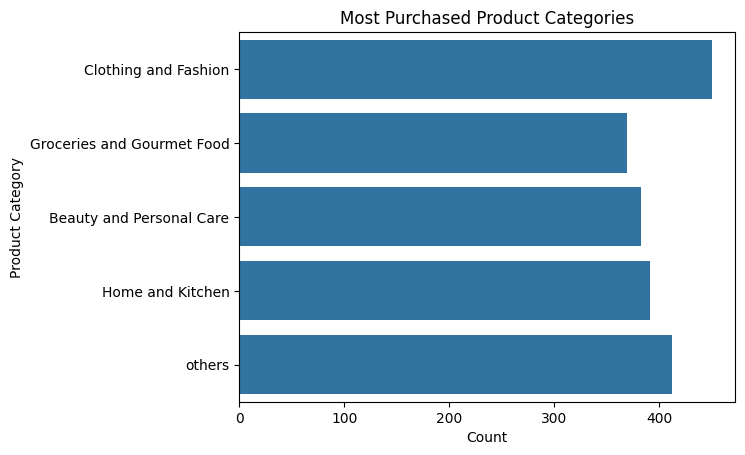

In [228]:
# Purchase Categories
categories = df['Purchase_Categories'].str.split(';').explode() # seperating the data on the basis of ';' and the exploding it.

# plotting the countplot
sns.countplot(y = categories)
plt.title('Most Purchased Product Categories')
plt.xlabel('Count')
plt.ylabel('Product Category')
plt.show()

Customers frequently purchase across multiple categories, with Clothing and Fashion appearing most often, indicating strong cross-selling opportunities.

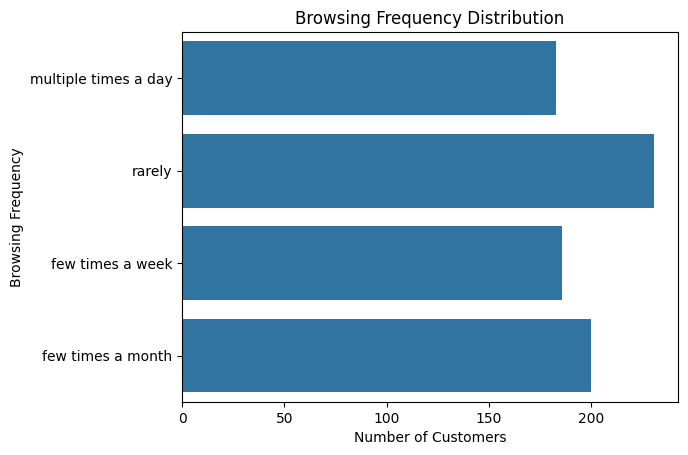

In [230]:
# Browsing frequency distribution
sns.countplot(y = df['Browsing_Frequency'], data = df)
plt.title('Browsing Frequency Distribution')
plt.xlabel('Number of Customers')
plt.ylabel('Browsing Frequency')
plt.show()

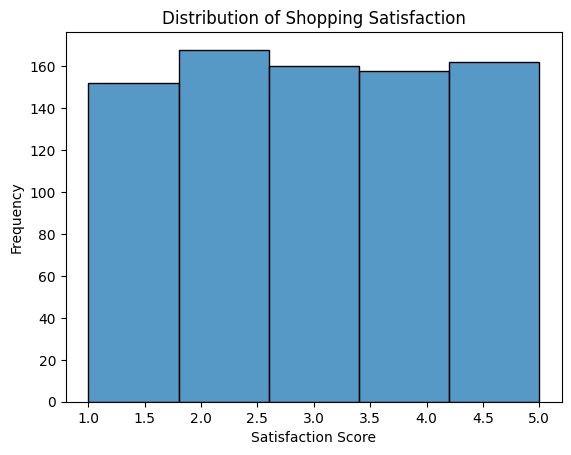

In [231]:
# Satisfaction levels
sns.histplot(x = df['Shopping_Satisfaction'], bins = 5,data = df)
plt.title('Distribution of Shopping Satisfaction')
plt.xlabel('Satisfaction Score')
plt.ylabel('Frequency')
plt.show()

Amazon provides a generally stable shopping experience, but a significant portion of customers remain only moderately satisfied or slightly dissatisfied. This highlights an opportunity to improve service quality and personalization to shift more customers toward higher satisfaction levels.

In [234]:
# Correlation between Recommendation Usefulness and Satisfaction
corr_cols = [
    'Shopping_Satisfaction',
    'Recommendation_Frequency_Score',
    'Customer_Reviews_Importance',
    'Rating_Accuracy'
]

In [236]:
corr_matrix = df[corr_cols].corr()

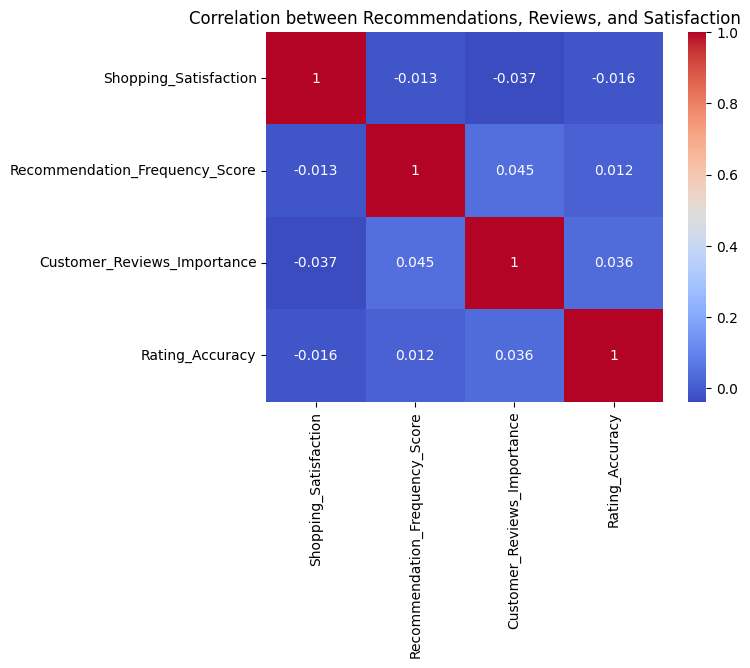

In [237]:
sns.heatmap(corr_matrix, annot = True, cmap='coolwarm')
plt.title('Correlation between Recommendations, Reviews, and Satisfaction')
plt.show()

Correlations are generally negative to weak, indicating that recommendation quality and review trust does not influence customer satisfaction and that satisfaction is likely influenced by other factors such as pricing, delivery experience, and service quality.

The findings from the analysis were consolidated into a clear and visually appealing dashboard using charts and plots to highlight customer demographics, purchasing behavior, satisfaction levels, and recommendation insights. The visualizations provide an intuitive overview of key trends and support data-driven decision-making.

# Project Explanation Video
[Click here to watch the project explanation video](https://www.loom.com/share/49f6b49f81ab47c5bb1a2293f7c1118f)
